# THỰC HÀNH XÂY DỰNG MÔ HÌNH HỒI QUY TUYẾN TÍNH
## TUẦN 2 — Bài tập 1, 2 và 3
Bộ dữ liệu Diabetes của scikit-learn. Notebook đi theo quy trình của giảng viên: chuẩn bị, khảo sát dữ liệu, huấn luyện, đánh giá, nhận xét. Phạm vi gồm ba bài tập Diabetes; không làm bài kc_house_data.

# PHẦN 1. CHUẨN BỊ MÔI TRƯỜNG
## Bước 1. Import thư viện và nạp dữ liệu

In [1]:
import sys, warnings, time
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, sklearn
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
RANDOM_STATE=42
d=load_diabetes(as_frame=True); X=d.data.copy(); y=d.target.copy(); df=X.copy(); df['target']=y
features=['bmi','bp','s5']
print('Python',sys.version.split()[0],'pandas',pd.__version__,'sklearn',sklearn.__version__)
print('Kích thước:',df.shape); display(df.head())

Python 3.12.14 pandas 2.3.3 sklearn 1.7.2
Kích thước: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


        age       sex       bmi        bp  ...        s4        s5        s6  target
0  0.038076  0.050680  0.061696  0.021872  ... -0.002592  0.019907 -0.017646   151.0
1 -0.001882 -0.044642 -0.051474 -0.026328  ... -0.039493 -0.068332 -0.092204    75.0
2  0.085299  0.050680  0.044451 -0.005670  ... -0.002592  0.002861 -0.025930   141.0
3 -0.089063 -0.044642 -0.011595 -0.036656  ...  0.034309  0.022688 -0.009362   206.0
4  0.005383 -0.044642 -0.036385  0.021872  ... -0.002592 -0.031988 -0.046641   135.0

[5 rows x 11 columns]

# PHẦN 2. BÀI 1 — PHÂN TÍCH DỮ LIỆU
## Bước 2. Kiểu dữ liệu, giá trị thiếu và thống kê mô tả

In [2]:
print('Kiểu dữ liệu:'); display(df.dtypes.to_frame('Kiểu'))
print('Giá trị thiếu:'); display(df.isna().sum().to_frame('Số thiếu'))
display(df[features+['target']].describe().T.round(3))

Kiểu dữ liệu:
Giá trị thiếu:


,Kiểu
age,float64
sex,float64
bmi,float64
bp,float64
s1,float64
s2,float64
s3,float64
s4,float64
s5,float64
s6,float64


           Kiểu
age     float64
sex     float64
bmi     float64
bp      float64
s1      float64
s2      float64
s3      float64
s4      float64
s5      float64
s6      float64
target  float64

,Số thiếu
age,0
sex,0
bmi,0
bp,0
s1,0
s2,0
s3,0
s4,0
s5,0
s6,0


        Số thiếu
age            0
sex            0
bmi            0
bp             0
s1             0
s2             0
s3             0
s4             0
s5             0
s6             0
target         0

,count,mean,std,min,25%,50%,75%,max
bmi,442.0,-0.000,0.048,-0.090,-0.034,-0.007,0.031,0.171
bp,442.0,-0.000,0.048,-0.112,-0.037,-0.006,0.036,0.132
s5,442.0,0.000,0.048,-0.126,-0.033,-0.002,0.032,0.134
target,442.0,152.133,77.093,25.000,87.000,140.500,211.500,346.000


        count     mean     std     min     25%      50%      75%      max
bmi     442.0   -0.000   0.048  -0.090  -0.034   -0.007    0.031    0.171
bp      442.0   -0.000   0.048  -0.112  -0.037   -0.006    0.036    0.132
s5      442.0    0.000   0.048  -0.126  -0.033   -0.002    0.032    0.134
target  442.0  152.133  77.093  25.000  87.000  140.500  211.500  346.000

## Bước 3. Histogram, ngoại lệ IQR và tương quan Pearson
IQR dùng để đánh dấu ngoại lệ, không loại bỏ điểm dữ liệu. Giá trị âm là bình thường vì các đặc trưng Diabetes đã được chuẩn hóa trong bộ dữ liệu gốc.

,Ngoại lệ IQR,Min,Max
Đặc trưng,,,
bmi,3,-0.090,0.171
bp,0,-0.112,0.132
s5,4,-0.126,0.134


           Ngoại lệ IQR    Min    Max
Đặc trưng                            
bmi                   3 -0.090  0.171
bp                    0 -0.112  0.132
s5                    4 -0.126  0.134

,bmi,bp,s5,target
bmi,1.000,0.395,0.446,0.586
bp,0.395,1.000,0.393,0.441
s5,0.446,0.393,1.000,0.566
target,0.586,0.441,0.566,1.000


          bmi     bp     s5  target
bmi     1.000  0.395  0.446   0.586
bp      0.395  1.000  0.393   0.441
s5      0.446  0.393  1.000   0.566
target  0.586  0.441  0.566   1.000

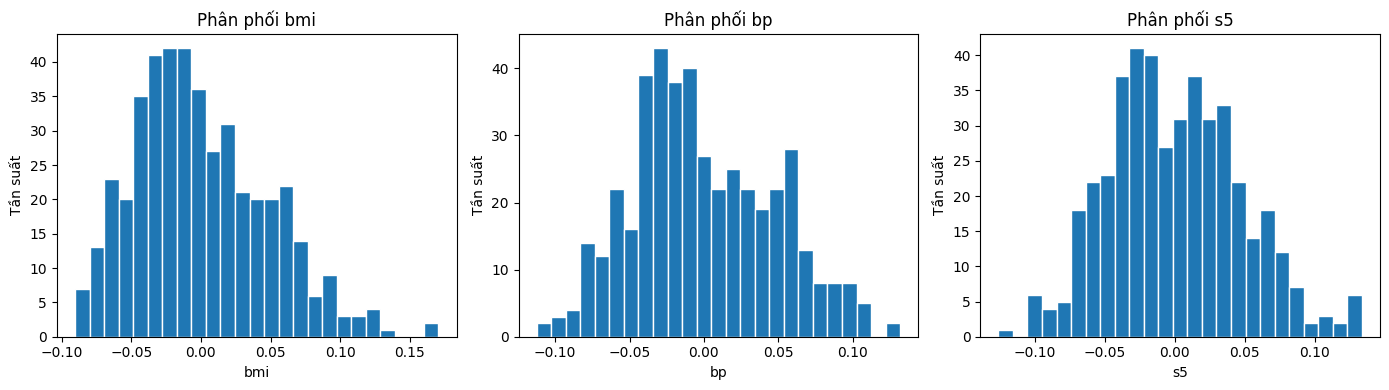

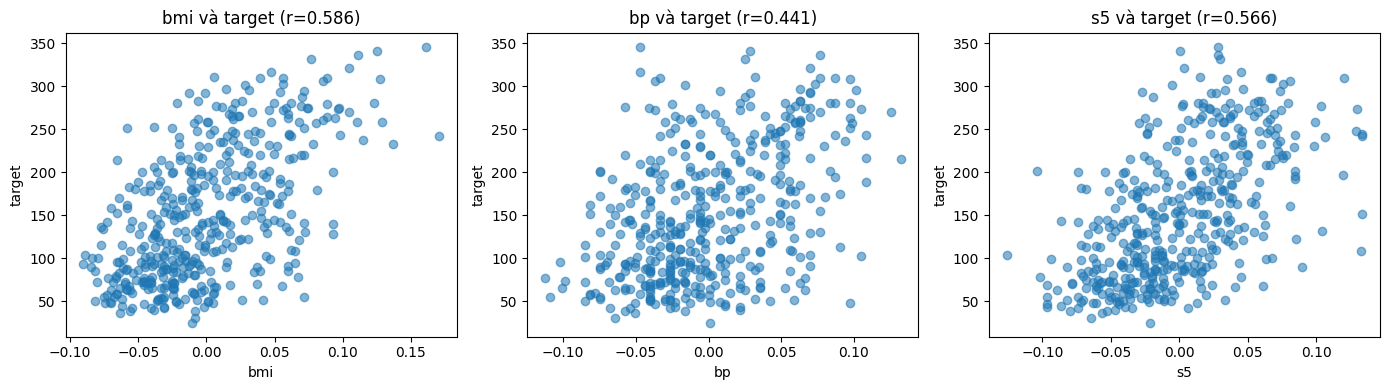

In [3]:
fig,axes=plt.subplots(1,3,figsize=(14,4)); out=[]
for ax,col in zip(axes,features):
 v=df[col]; ax.hist(v,bins=25,edgecolor='white'); ax.set(title='Phân phối '+col,xlabel=col,ylabel='Tần suất')
 q1,q3=v.quantile([.25,.75]); iq=q3-q1; lo=q1-1.5*iq; hi=q3+1.5*iq
 out.append({'Đặc trưng':col,'Ngoại lệ IQR':int(((v<lo)|(v>hi)).sum()),'Min':v.min(),'Max':v.max()})
plt.tight_layout();plt.show()
display(pd.DataFrame(out).set_index('Đặc trưng').round(3))
corr=df[features+['target']].corr();display(corr.round(3))
fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,col in zip(axes,features):
 ax.scatter(df[col],y,alpha=.55);ax.set(title=f'{col} và target (r={corr.loc[col,"target"]:.3f})',xlabel=col,ylabel='target')
plt.tight_layout();plt.show()

# PHẦN 3. BÀI 2 — SO SÁNH BỘ ĐẶC TRƯNG
## Bước 4. Chia Train/Test và chọn Top 5 chỉ từ Train

In [4]:
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=.20,random_state=RANDOM_STATE)
top_corr=Xtr.assign(target=ytr).corr()['target'].drop('target').abs().sort_values(ascending=False)
top5=top_corr.head(5).index.tolist()
feature_sets={'bmi':['bmi'],'bmi + bp':['bmi','bp'],'Top 5 (Train)':top5,'10 đặc trưng':X.columns.tolist()}
print('Top 5 chọn từ Train:',top5);display(top_corr.to_frame('|r| Train').round(4))

Top 5 chọn từ Train: ['bmi', 's5', 'bp', 's4', 's6']


,|r| Train
bmi,0.6048
s5,0.5522
bp,0.4448
s4,0.4251
s6,0.3904
s3,0.3840
s1,0.1995
age,0.1965
s2,0.1549
sex,0.0071


     |r| Train
bmi     0.6048
s5      0.5522
bp      0.4448
s4      0.4251
s6      0.3904
s3      0.3840
s1      0.1995
age     0.1965
s2      0.1549
sex     0.0071

## Bước 5. Huấn luyện Linear Regression và so sánh MAE, RMSE, R²

RMSE thấp nhất: Top 5 (Train) 53.849


,Số đặc trưng,MAE,RMSE,R²
Bộ đặc trưng,,,,
Top 5 (Train),5,44.3288,53.8493,0.4527
10 đặc trưng,10,42.7941,53.8534,0.4526
bmi + bp,2,50.0441,61.1597,0.2940
bmi,1,52.2600,63.7325,0.2334


               Số đặc trưng      MAE     RMSE      R²
Bộ đặc trưng                                         
Top 5 (Train)             5  44.3288  53.8493  0.4527
10 đặc trưng             10  42.7941  53.8534  0.4526
bmi + bp                  2  50.0441  61.1597  0.2940
bmi                       1  52.2600  63.7325  0.2334

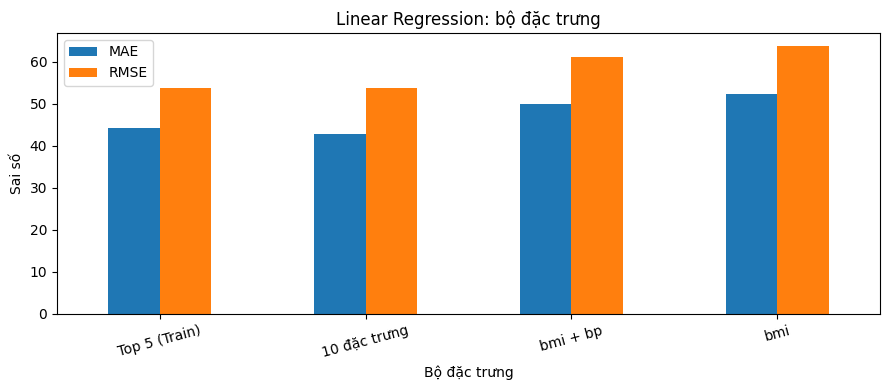

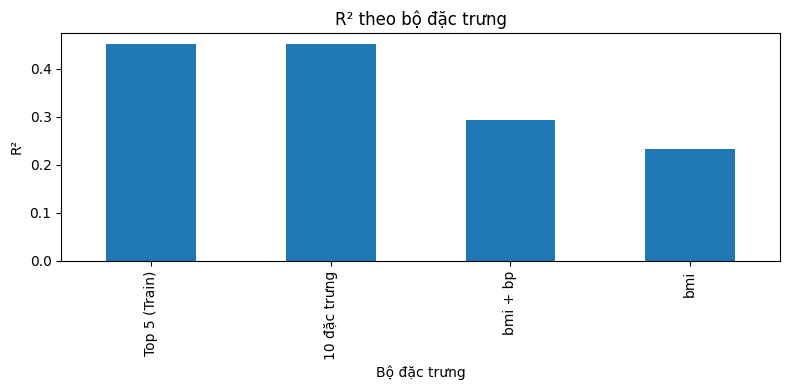

In [5]:
rows=[]
for name,cols in feature_sets.items():
 model=LinearRegression().fit(Xtr[cols],ytr);p=model.predict(Xte[cols])
 rows.append({'Bộ đặc trưng':name,'Số đặc trưng':len(cols),'MAE':mean_absolute_error(yte,p),'RMSE':mean_squared_error(yte,p)**.5,'R²':r2_score(yte,p)})
feature_results=pd.DataFrame(rows).set_index('Bộ đặc trưng').sort_values('RMSE');display(feature_results.round(4))
ax=feature_results[['MAE','RMSE']].plot(kind='bar',figsize=(9,4));ax.set(title='Linear Regression: bộ đặc trưng',ylabel='Sai số');plt.xticks(rotation=15);plt.tight_layout();plt.show()
feature_results['R²'].plot(kind='bar',figsize=(8,4),title='R² theo bộ đặc trưng',ylabel='R²');plt.tight_layout();plt.show()
print('RMSE thấp nhất:',feature_results.index[0],round(feature_results.iloc[0]['RMSE'],3))

# PHẦN 4. BÀI 3 — SO SÁNH THUẬT TOÁN HỒI QUY
## Bước 6. Huấn luyện năm thuật toán
Chuẩn hóa nằm trong Pipeline cho mô hình tuyến tính và SVR. Cây quyết định và Gradient Boosting không cần scale theo thang đo.

Tốt nhất theo RMSE Test: SVR


,MAE Train,RMSE Train,R² Train,MAE Test,RMSE Test,R² Test
Mô hình,,,,,,
SVR,42.0812,53.1970,0.5343,41.3197,51.7918,0.4937
Ridge Regression,43.4947,53.5751,0.5276,42.8120,53.7775,0.4541
Gradient Boosting,25.3517,31.5772,0.8359,44.6033,53.8371,0.4529
Linear Regression,43.4835,53.5588,0.5279,42.7941,53.8534,0.4526
Decision Tree,40.0738,50.2420,0.5846,47.0454,59.7408,0.3264


                   MAE Train  RMSE Train  ...  RMSE Test  R² Test
Mô hình                                   ...                    
SVR                  42.0812     53.1970  ...    51.7918   0.4937
Ridge Regression     43.4947     53.5751  ...    53.7775   0.4541
Gradient Boosting    25.3517     31.5772  ...    53.8371   0.4529
Linear Regression    43.4835     53.5588  ...    53.8534   0.4526
Decision Tree        40.0738     50.2420  ...    59.7408   0.3264

[5 rows x 6 columns]

,Chênh lệch R²
Mô hình,
SVR,0.0406
Ridge Regression,0.0735
Gradient Boosting,0.3830
Linear Regression,0.0753
Decision Tree,0.2582


                   Chênh lệch R²
Mô hình                         
SVR                       0.0406
Ridge Regression          0.0735
Gradient Boosting         0.3830
Linear Regression         0.0753
Decision Tree             0.2582

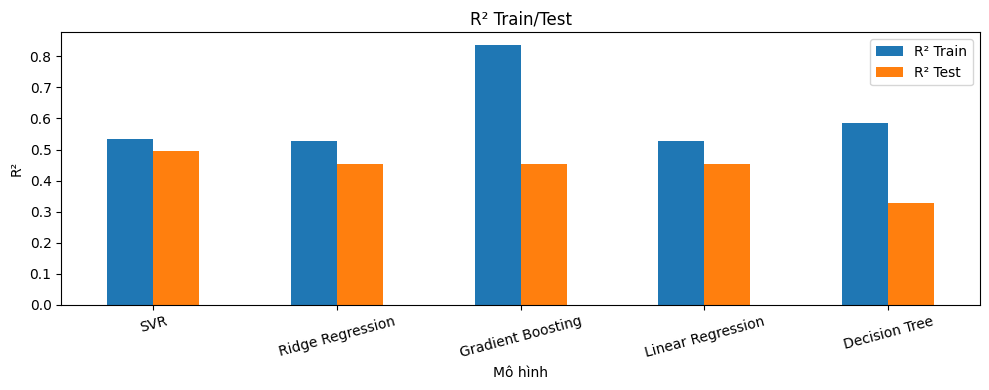

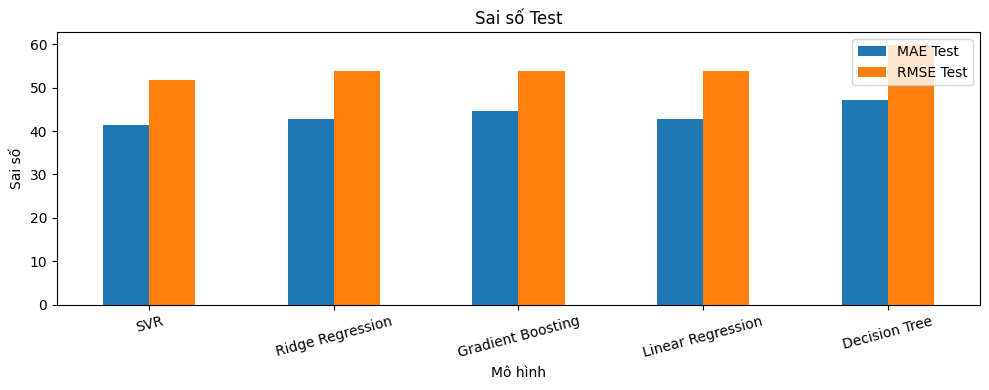

In [6]:
models={'Linear Regression':make_pipeline(StandardScaler(),LinearRegression()),
'Ridge Regression':make_pipeline(StandardScaler(),Ridge(alpha=1.0)),
'Decision Tree':DecisionTreeRegressor(max_depth=4,random_state=RANDOM_STATE),
'SVR':make_pipeline(StandardScaler(),SVR(C=10)),
'Gradient Boosting':GradientBoostingRegressor(random_state=RANDOM_STATE)}
rows=[]
for name,model in models.items():
 model.fit(Xtr,ytr); a=model.predict(Xtr); b=model.predict(Xte)
 rows.append({'Mô hình':name,'MAE Train':mean_absolute_error(ytr,a),'RMSE Train':mean_squared_error(ytr,a)**.5,'R² Train':r2_score(ytr,a),'MAE Test':mean_absolute_error(yte,b),'RMSE Test':mean_squared_error(yte,b)**.5,'R² Test':r2_score(yte,b)})
model_results=pd.DataFrame(rows).set_index('Mô hình').sort_values('RMSE Test');display(model_results.round(4))
ax=model_results[['R² Train','R² Test']].plot(kind='bar',figsize=(10,4));ax.set(title='R² Train/Test',ylabel='R²');plt.xticks(rotation=15);plt.tight_layout();plt.show()
ax=model_results[['MAE Test','RMSE Test']].plot(kind='bar',figsize=(10,4));ax.set(title='Sai số Test',ylabel='Sai số');plt.xticks(rotation=15);plt.tight_layout();plt.show()
print('Tốt nhất theo RMSE Test:',model_results.index[0])
display((model_results['R² Train']-model_results['R² Test']).rename('Chênh lệch R²').to_frame().round(4))

### Kết luận Tuần 2
Đã hoàn thành Bài 1 phân tích ba đặc trưng, Bài 2 so sánh bốn bộ đặc trưng và Bài 3 so sánh năm thuật toán. Kết luận được sinh từ bảng kết quả ở lần chạy hiện tại; độ chênh R² Train/Test được dùng để nhận xét overfitting cùng với sai số Test.